![Banner](../images/09_05_banner_rs_hyperspect.png)


# Greenhouse Gas Plume Detection

Methane absorbs sunlight in narrow lines between 2200 and 2400 nm. An imaging spectrometer that
resolves this region sees a plume as a slight darkening of the radiance in exactly the methane
bands, a few percent at most. This notebook builds a methane unit absorption spectrum from HITRAN
line data, maps the methane enhancement over oil fields in eastern Syria with a matched filter on
Tanager radiance, segments the plumes, computes their integrated mass enhancement and emission rates,
and compares every step with the plumes that Carbon Mapper published for the same scene.


## Overview

### Why methane, why imaging spectroscopy

Methane is the second largest contributor to human caused warming, with about 80 times the warming
effect of CO₂ over 20 years. A large share of anthropogenic emissions comes from a small number of
**point sources**: leaking wells, compressors, pipelines, flares, coal mine vents and landfills.
Finding them requires pixels of tens of metres, which imaging spectrometers such as AVIRIS-NG, EMIT,
PRISMA, EnMAP and Tanager provide; Tanager was launched by the Carbon Mapper coalition specifically
to find and quantify such plumes.

### The physics

Along the light path (sun to ground to sensor) the radiance is attenuated by methane following the
Beer Lambert law. A plume adds an enhancement **ΔX** (in ppm·m: the extra concentration in ppm times
the path length in metres) on top of the background column. For small enhancements the change in
log radiance is linear:

$$\ln L(\lambda) \approx \ln L_0(\lambda) + k(\lambda)\,\Delta X$$

where **k(λ)** is the **unit absorption spectrum** (per ppm·m): the band averaged change in log
radiance per unit enhancement, computed from the methane absorption cross sections, the background
atmosphere and the sun and view geometry (the air mass factor).

### The matched filter

With the background mean radiance **μ** and covariance **Σ**, the target is `t = μ ⊙ k` and the
enhancement estimate is (Thompson et al. 2016)

$$\widehat{\Delta X} = \frac{(\mathbf{x} - \boldsymbol\mu)^T \Sigma^{-1} \mathbf{t}}{\mathbf{t}^T \Sigma^{-1} \mathbf{t}}$$

the matched filter of notebook 09_05_08 with a physical target, so the score is directly in ppm·m.
For pushbroom data in sensor geometry the statistics are computed per detector column; for an
orthorectified product they are computed over the scene.

### From enhancement to emission rate

The **integrated mass enhancement (IME)** sums the excess methane mass over the plume:
`IME = Σ ΔX · 10⁻⁶ · ρ_CH4 · A_pixel`. A simple mass balance (Varon et al. 2018) gives the emission
rate `Q = IME · U / L`, with an effective wind speed **U** (from weather models) and a plume length
scale **L**. Carbon Mapper reports `Q = IME · U / fetch`, where the fetch is the distance over which
the plume was integrated.

### Limitations

Bright and dark surfaces with SWIR structure (some soils, paints, oil stains) produce false
enhancements; the background statistics must exclude plumes; wind uncertainty usually dominates the
emission uncertainty; and the simple k used here ignores water vapour and surface pressure variations.


## Methane Plumes with GeoLattice

`hs.gas_matched_filter` estimates the enhancement from radiance and a unit absorption spectrum,
`hs.plume_mask` segments plumes, `hs.plume_ime` integrates their mass and `hs.emission_rate` converts
IME to kg/h. The unit absorption spectrum is computed here from HITRAN line parameters with HAPI, the
HITRAN Application Programming Interface (`pip install hitran-api`).

### Learning objectives

1. Compute methane absorption cross sections from HITRAN and a unit absorption spectrum on Tanager
   bands for the scene's geometry.
2. Run the matched filter on Tanager radiance and interpret the enhancement map and its noise.
3. Compare the result with Carbon Mapper's quick look methane product.
4. Segment plumes, compute IME and emission rates, and compare them with published values.
5. Recognise false positives and the main sources of uncertainty.

### Data

| File | Content |
|---|---|
| `Tanger/GHG-plumes/20241004_081921_28_4001/*_ortho_radiance_hdf5.h5` | Tanager TOA radiance, 4 October 2024, eastern Syria (about 35.3° N, 40.4° E) |
| `*_ortho_ql_ch4.tif` | Carbon Mapper quick look methane enhancement (8 bit, scaled) |
| `*_ql_ch4_json.geojson` | Carbon Mapper plume list: source location, IME, fetch, wind and emission rate with uncertainty |
| `hitran/CH4.data`, `hitran/CH4.header` | HITRAN methane lines, 3950 to 4800 cm⁻¹ (about 2080 to 2530 nm), fetched with HAPI on first use |

### Contents

- Setup
- Methane absorption from HITRAN
- The unit absorption spectrum
- The enhancement map
- Comparison with Carbon Mapper
- Plumes, IME and emission rates
- False positives and uncertainty
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README. It also uses `hitran-api`, which no GeoLattice option installs: `pip install hitran-api`.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

import json  # plume attributes
import time  # timing
import geopandas as gpd  # plume points
import rioxarray  # reproject the quick look product
from scipy import ndimage as ndi  # labelling and filtering

GHG = next((TANAGER / "GHG-plumes").iterdir())  # scene folder
HITRAN = DATA / "hitran"  # cache for HITRAN line data

GeoLattice 0.3.43


## Methane absorption from HITRAN

HAPI downloads the line list once (about 9 MB) and caches it in `Data/08_remote_sensing/08_05_HyperSpectral/hitran`. Absorption cross
sections are computed on a 0.01 cm⁻¹ grid with Voigt line shapes for a representative lower
troposphere (0.85 atm, 280 K).


In [2]:
import contextlib, io  # silence HAPI's log messages
with contextlib.redirect_stdout(io.StringIO()):
    import hapi  # HITRAN Application Programming Interface

    HITRAN.mkdir(exist_ok=True)
    hapi.db_begin(str(HITRAN))  # use the local cache
    if "CH4" not in hapi.tableList():
        hapi.fetch("CH4", 6, 1, 3950, 4800)  # molecule 6 (CH4), main isotopologue, wavenumber range in cm-1
    t0 = time.perf_counter()
    nu, xsec = hapi.absorptionCoefficient_Voigt(SourceTables="CH4", WavenumberRange=[3950, 4800], WavenumberStep=0.01,
                                                Environment={"p": 0.85, "T": 280.0}, Diluent={"air": 1.0},
                                                HITRAN_units=True)  # cross section, cm2 per molecule
print(f"{len(nu):,} wavenumbers in {time.perf_counter() - t0:.0f} s | peak cross section {xsec.max():.2e} cm2")
wl_hi = 1e7 / nu  # wavenumber (cm-1) to wavelength (nm)

85,001 wavenumbers in 14 s | peak cross section 3.90e-20 cm2


## The unit absorption spectrum

The radiance is read for 2100 to 2500 nm, where methane absorbs. The sun and view zenith angles set
the air mass factor (the two way path relative to the vertical). The high resolution transmittance of
the background atmosphere (1.9 ppm methane) and of the same atmosphere with an extra 1000 ppm·m are
both convolved with Tanager's band responses; the difference of their logarithms per ppm·m is the
unit absorption spectrum.


(81, 1040, 943) | sun zenith 41.4, view zenith 2.8, air mass factor 2.33
strongest absorption -2.14e-05 per ppm·m at 2370 nm (1000 ppm·m darken that band by 2.1 %)


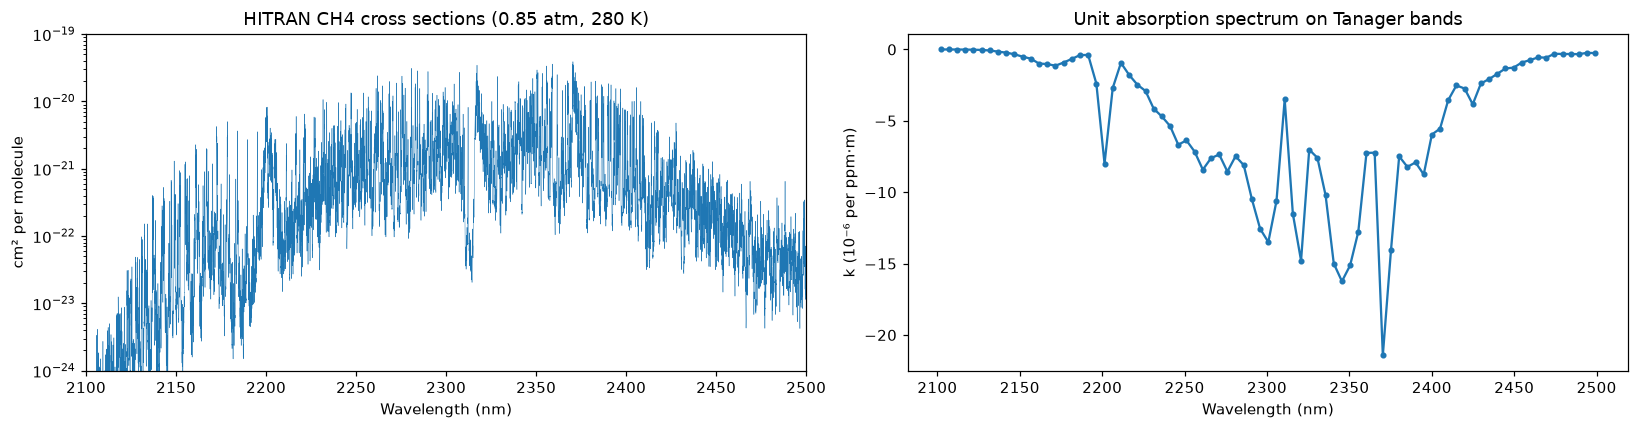

In [3]:
rad_file = next(GHG.glob("*_ortho_radiance_hdf5.h5"))
rad = hs.read_tanager(rad_file, wavelength_range=(2100, 2500))  # TOA radiance, W m-2 sr-1 um-1
anc = hs.read_tanager_ancillary(rad_file)
sza, vza = float(anc["sun_zenith"].mean()), float(anc["sensor_zenith"].mean())
amf = 1 / np.cos(np.radians(sza)) + 1 / np.cos(np.radians(vza))  # two way air mass factor
print(rad.shape, f"| sun zenith {sza:.1f}, view zenith {vza:.1f}, air mass factor {amf:.2f}")

N_PPMM = 1e-6 * 2.5e25 * 1e-4  # CH4 molecules per cm2 for 1 ppm·m (air number density 2.5e25 m-3)
background = 1.9e-6 * 2.15e25  # vertical background CH4 column (molecules cm-2): 1.9 ppm of the air column
T_bg = np.exp(-xsec * background * amf)  # background transmittance
T_plume = T_bg * np.exp(-xsec * N_PPMM * 1000 * amf)  # with an extra 1000 ppm·m
wl, fwhm = hs.wavelengths(rad), rad["fwhm"].values


def to_bands(T):
    """Band averaged transmittance: Gaussian response of each Tanager band."""
    out = np.empty(len(wl))
    for i, (c, f) in enumerate(zip(wl, fwhm)):
        w = np.exp(-0.5 * ((wl_hi - c) / (f / 2.3548)) ** 2)
        out[i] = (w * T).sum() / w.sum()
    return out


k = (np.log(to_bands(T_plume)) - np.log(to_bands(T_bg))) / 1000  # per ppm·m
print(f"strongest absorption {k.min():.2e} per ppm·m at {wl[np.argmin(k)]:.0f} nm "
      f"(1000 ppm·m darken that band by {100 * (1 - np.exp(1000 * k.min())):.1f} %)")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(wl_hi, xsec, lw=0.3)
axes[0].set(xlim=(2100, 2500), yscale="log", ylim=(1e-24, 1e-19), xlabel="Wavelength (nm)", ylabel="cm² per molecule",
            title="HITRAN CH4 cross sections (0.85 atm, 280 K)")
axes[1].plot(wl, k * 1e6, "o-", ms=3)
axes[1].set(xlabel="Wavelength (nm)", ylabel="k (10⁻⁶ per ppm·m)", title="Unit absorption spectrum on Tanager bands")
plt.tight_layout()
plt.show()

Thousands of individual lines make up the methane band; at Tanager's 5 to 6 nm resolution they merge
into a smooth unit absorption spectrum with its strongest values near 2300 to 2370 nm. A 1000 ppm·m
plume darkens the strongest band by about two percent, which is why the detection works through
statistics rather than by looking at single spectra.


## The enhancement map

The matched filter uses all good bands between 2100 and 2500 nm and the whole scene as background
(the product is orthorectified, so the per column option is off).


matched filter in 0.9 s | median 1 ppm·m, robust SD 292 ppm·m, 99.9th percentile 1513 ppm·m


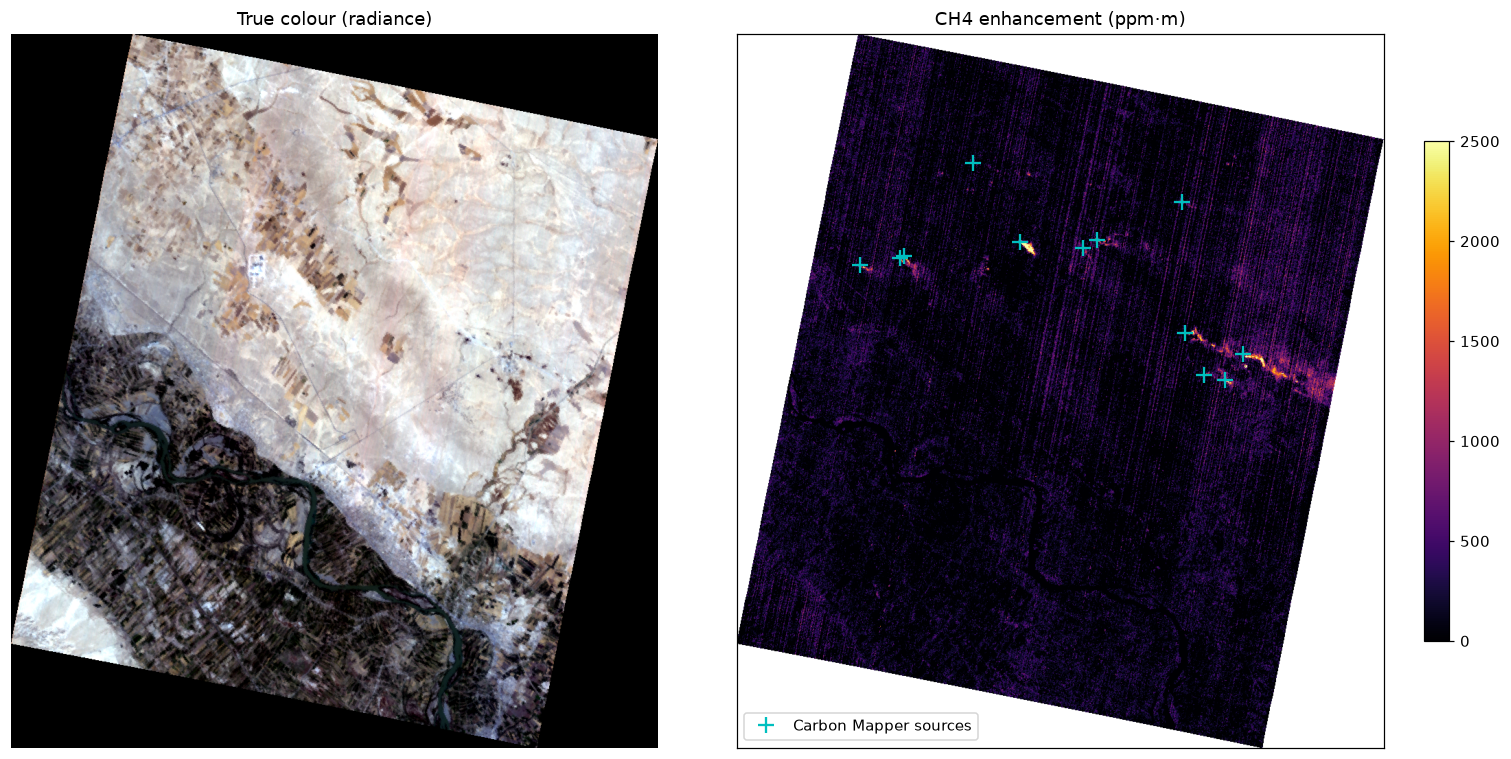

In [4]:
t0 = time.perf_counter()
enh = hs.gas_matched_filter(rad, k, window=(2100, 2500), columnwise=False).rio.write_crs(rad.rio.crs)
e = enh.values
med = float(np.nanmedian(e)); sd = float(np.nanmedian(np.abs(e - med)) * 1.4826)  # robust centre and spread
print(f"matched filter in {time.perf_counter() - t0:.1f} s | median {med:.0f} ppm·m, robust SD {sd:.0f} ppm·m, "
      f"99.9th percentile {np.nanpercentile(e, 99.9):.0f} ppm·m")
plumes = gpd.read_file(next(GHG.glob("*_ql_ch4_json.geojson"))).to_crs(rad.rio.crs)  # Carbon Mapper plumes
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
hs.plot_rgb(hs.read_tanager(rad_file, bands=[55, 37, 17]), (651, 561, 461), ax=axes[0], title="True colour (radiance)")
im = axes[1].imshow(e, cmap="inferno", vmin=0, vmax=2500,
                    extent=[float(enh.x[0]), float(enh.x[-1]), float(enh.y[-1]), float(enh.y[0])])
axes[1].plot(plumes.geometry.x, plumes.geometry.y, "c+", ms=10, mew=1.5, label="Carbon Mapper sources")
axes[1].set_title("CH4 enhancement (ppm·m)"); axes[1].legend(loc="lower left"); axes[1].set_xticks([]); axes[1].set_yticks([])
plt.colorbar(im, ax=axes[1], shrink=0.7)
plt.tight_layout()
plt.show()

The background noise of the enhancement map is about 300 ppm·m (the robust standard deviation), and
the strongest plumes reach several thousand ppm·m. Elongated plumes stretch downwind (to the south
east) from the Carbon Mapper source points in the oil field on the desert plateau. Two artefacts are
visible. Fine vertical stripes run along track: each detector column has a slightly different
response, and with scene wide statistics on the ortho grid it is not removed (per column statistics
in sensor geometry, `columnwise=True` on a basic product, address this). And the Euphrates and its
irrigated valley appear slightly negative, because dark water and wet fields have little SWIR signal
and a different spectral shape from the desert that dominates the background statistics.


## Comparison with Carbon Mapper

Carbon Mapper's quick look product is an 8 bit image (scaled values without units) on a grid offset
by a pixel or two, so it is reprojected onto the enhancement grid before comparison.


pixel correlation with the quick look: r = 0.77


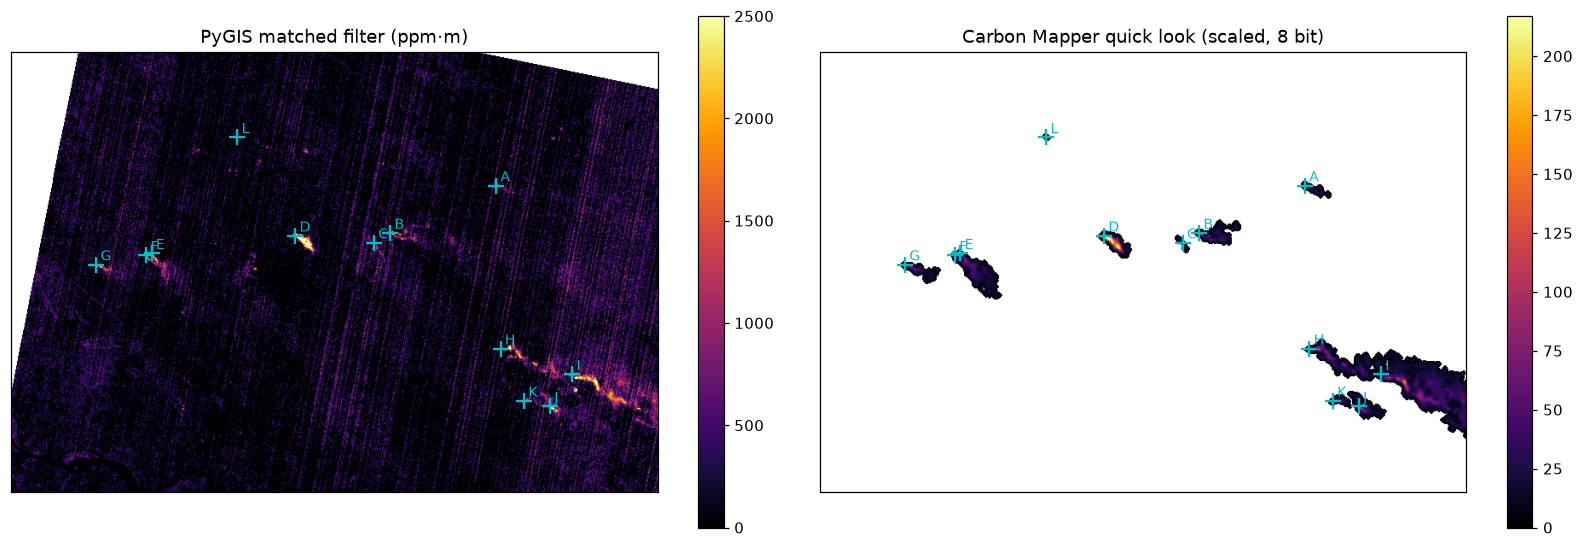

In [5]:
ql = rioxarray.open_rasterio(next(GHG.glob("*_ortho_ql_ch4.tif")), masked=True).squeeze().rio.reproject_match(enh)
q = ql.values
ok = np.isfinite(e) & np.isfinite(q)
print(f"pixel correlation with the quick look: r = {np.corrcoef(e[ok], q[ok])[0, 1]:.2f}")
x0, x1, y0, y1 = plumes.geometry.x.min() - 3000, plumes.geometry.x.max() + 3000, plumes.geometry.y.min() - 3000, plumes.geometry.y.max() + 3000
zoom = dict(x=slice(x0, x1), y=slice(y1, y0))  # area around the sources
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (img, t, vmax) in zip(axes, [(enh.sel(**zoom), "GeoLattice matched filter (ppm·m)", 2500),
                                     (ql.sel(**zoom), "Carbon Mapper quick look (scaled, 8 bit)", np.nanpercentile(q, 99.9))]):
    im = ax.imshow(img, cmap="inferno", vmin=0, vmax=vmax, extent=[x0, x1, y0, y1])
    ax.plot(plumes.geometry.x, plumes.geometry.y, "c+", ms=10, mew=1.5)
    for _, p in plumes.iterrows():
        ax.text(p.geometry.x + 150, p.geometry.y + 150, p["plume_id"][-1], color="c", fontsize=9)
    ax.set_title(t); ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()

The two maps show the same plumes in the same places. The quick look only has values inside Carbon
Mapper's plume masks (everything else is no data), so the correlation of r = 0.77 is measured over
those plume pixels: within the plumes, the two retrievals agree on where the enhancement is highest,
although the methods differ (Carbon Mapper uses its own processing, target spectra and filtering).
The GeoLattice map keeps the full resolution noise and the stripes.


## Plumes, IME and emission rates

`hs.plume_mask` segments the whole map automatically. For a like for like comparison with the
published numbers, each Carbon Mapper plume is then integrated the same way: pixels within the plume's
fetch radius that exceed the background by 1.5 robust standard deviations (after a 3 by 3 median
filter) and are connected to the source, summed with `hs.plume_ime` and converted with
`hs.emission_rate` using Carbon Mapper's wind speed and fetch.


In [6]:
labels, table = hs.plume_mask(enh, sigma=3.0, min_pixels=10)  # automatic segmentation of the whole scene
print(f"automatic plume_mask: {len(table)} candidate plumes above median + 3 MAD")
display(table.sort_values("n_pixels", ascending=False).head(6).round(0))

X, Y = np.meshgrid(enh.x.values, enh.y.values)
smooth = ndi.median_filter(np.nan_to_num(e, nan=med), 3)  # suppress single pixel noise
rows, masks = [], np.zeros(e.shape, int)
for i, p in plumes.iterrows():
    d = np.hypot(X - p.geometry.x, Y - p.geometry.y)  # distance to the source (m)
    cand = (d <= p["fetch"]) & (smooth > med + 1.5 * sd)
    lab, _ = ndi.label(cand)
    touching = np.unique(lab[(d <= 150) & cand])  # components within 150 m of the source
    keep = np.isin(lab, touching[touching > 0])
    masks[keep] = i + 1
    res = hs.plume_ime(enh - med, enh.copy(data=keep.astype(int)), plume=1)  # IME of the masked pixels
    q_ours = hs.emission_rate(res["ime_kg"], p["wind_speed_avg"], p["fetch"])  # kg/h, Carbon Mapper wind and fetch
    rows.append({"plume": p["plume_id"][-1], "quality": p["plume_quality"], "pixels": res["n_pixels"],
                 "IME GeoLattice (kg)": res["ime_kg"], "IME Carbon Mapper (kg)": p["ime"],
                 "Q GeoLattice (kg/h)": q_ours, "Q Carbon Mapper (kg/h)": p["emission"], "Q uncertainty CM": p["emission_uncertainty"]})
res_tab = pd.DataFrame(rows).set_index("plume")
res_tab.round(0)

automatic plume_mask: 45 candidate plumes above median + 3 MAD


,plume,n_pixels,max,mean,row,col,y,x
27,28,752,5389.0,1332.0,474,764,3907785.0,632085.0
7,8,275,7917.0,2718.0,302,412,3912945.0,621525.0
40,41,248,1645.0,937.0,504,842,3906885.0,634425.0
37,38,236,1585.0,973.0,508,870,3906765.0,635265.0
26,27,234,1509.0,889.0,473,792,3907815.0,632925.0
33,34,207,1584.0,888.0,496,833,3907125.0,634155.0


,quality,pixels,IME GeoLattice (kg),IME Carbon Mapper (kg),Q GeoLattice (kg/h),Q Carbon Mapper (kg/h),Q uncertainty CM
plume,,,,,,,
A,good,109,49.0,41.0,539.0,446.0,86.0
B,good,149,101.0,147.0,651.0,947.0,170.0
C,questionable,20,9.0,4.0,379.0,174.0,63.0
D,questionable,294,458.0,458.0,3191.0,3189.0,390.0
E,questionable,371,204.0,209.0,1124.0,1150.0,179.0
F,questionable,371,204.0,214.0,1098.0,1152.0,151.0
G,good,132,75.0,70.0,634.0,595.0,78.0
H,good,296,202.0,215.0,1158.0,1231.0,237.0
I,good,971,558.0,229.0,3343.0,1374.0,263.0


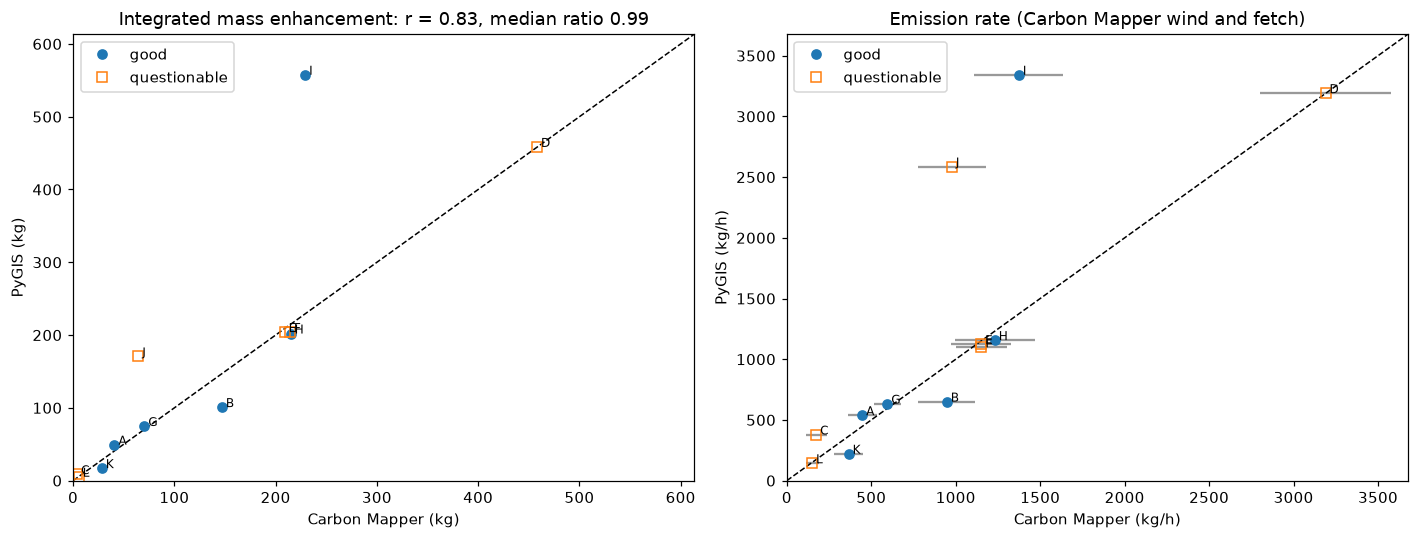

total emission of the 12 plumes: GeoLattice 15,068 kg/h, Carbon Mapper 11,750 kg/h


In [7]:
r = np.corrcoef(res_tab["IME GeoLattice (kg)"], res_tab["IME Carbon Mapper (kg)"])[0, 1]
ratio = (res_tab["IME GeoLattice (kg)"] / res_tab["IME Carbon Mapper (kg)"]).median()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (a, b, unit) in zip(axes, [("IME GeoLattice (kg)", "IME Carbon Mapper (kg)", "kg"), ("Q GeoLattice (kg/h)", "Q Carbon Mapper (kg/h)", "kg/h")]):
    good = res_tab["quality"] == "good"
    ax.errorbar(res_tab.loc[good, b], res_tab.loc[good, a], fmt="o", label="good")
    ax.errorbar(res_tab.loc[~good, b], res_tab.loc[~good, a], fmt="s", mfc="none", label="questionable")
    if unit == "kg/h":
        ax.errorbar(res_tab[b], res_tab[a], xerr=res_tab["Q uncertainty CM"], fmt="none", ecolor="0.6", zorder=0)
    lim = [0, 1.1 * max(res_tab[a].max(), res_tab[b].max())]
    ax.plot(lim, lim, "k--", lw=1)
    for name, row in res_tab.iterrows():
        ax.text(row[b], row[a], f" {name}", fontsize=8)
    ax.set(xlabel=f"Carbon Mapper ({unit})", ylabel=f"GeoLattice ({unit})", xlim=lim, ylim=lim); ax.legend()
axes[0].set_title(f"Integrated mass enhancement: r = {r:.2f}, median ratio {ratio:.2f}")
axes[1].set_title("Emission rate (Carbon Mapper wind and fetch)")
plt.tight_layout()
plt.show()
print(f"total emission of the 12 plumes: GeoLattice {res_tab['Q GeoLattice (kg/h)'].sum():,.0f} kg/h, "
      f"Carbon Mapper {res_tab['Q Carbon Mapper (kg/h)'].sum():,.0f} kg/h")

Read the table and scatter plots together. Across the twelve plumes the IME correlates with the
published values (r = 0.83) and the median ratio is 0.99, a close agreement for an independent
retrieval built from HITRAN line data and a simple atmosphere. Plumes A, D, E, F, G, H and L agree
within about 20 percent, inside or near Carbon Mapper's uncertainty bars (grey). The outliers are
instructive. I and J are two to three times too high: they sit in the long band of enhancement in
the south east, where several plumes merge, and a mask that grows from the source collects their
neighbours' methane too. E and F share one mask, because their sources are a few hundred metres
apart. B is too low, and the smallest plumes (C, K, L) are close to the noise. Separating
overlapping plumes is where analyst judgement and plume shape analysis come in. The total over all
plumes is about 30 percent higher than Carbon Mapper's, almost entirely because of I and J.


## False positives and uncertainty


automatic candidates: 45 | within 1.5 km of a Carbon Mapper source: 25 | elsewhere: 20


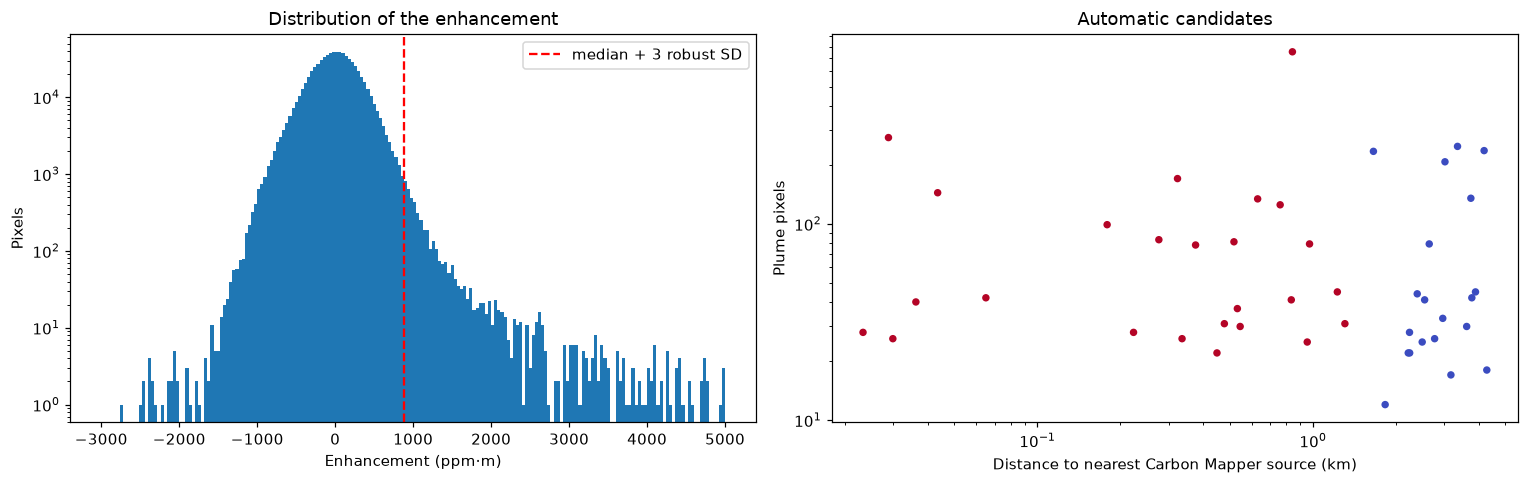

In [8]:
auto = table.copy()
X0, Y0 = auto["x"].to_numpy(), auto["y"].to_numpy()
dmin = np.min(np.hypot(X0[:, None] - plumes.geometry.x.to_numpy()[None, :], Y0[:, None] - plumes.geometry.y.to_numpy()[None, :]), 1)
auto["distance to nearest CM source (km)"] = dmin / 1000
near = auto["distance to nearest CM source (km)"] < 1.5
print(f"automatic candidates: {len(auto)} | within 1.5 km of a Carbon Mapper source: {int(near.sum())} | "
      f"elsewhere: {int((~near).sum())}")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(e[np.isfinite(e)], bins=200, range=(-3000, 5000), log=True)
axes[0].axvline(med + 3 * sd, color="r", ls="--", label="median + 3 robust SD")
axes[0].set(xlabel="Enhancement (ppm·m)", ylabel="Pixels", title="Distribution of the enhancement"); axes[0].legend()
axes[1].scatter(auto["distance to nearest CM source (km)"], auto["n_pixels"], c=near, cmap="coolwarm", s=15)
axes[1].set(xscale="log", yscale="log", xlabel="Distance to nearest Carbon Mapper source (km)", ylabel="Plume pixels",
            title="Automatic candidates")
plt.tight_layout()
plt.show()

The enhancement distribution is a Gaussian core (noise) with a long positive tail (plumes and false
positives). A fixed threshold keeps many small candidates far from any published source: most are
surface artefacts or noise clusters, a reminder that an automatic mask is a list of candidates, not
of plumes. Operational systems confirm plumes by their shape, their alignment with the wind,
repeated detection on other dates and inspection by analysts.

The emission rate inherits several uncertainties: the noise in ΔX, the choice of mask threshold (at
2 robust SD instead of 1.5 the IME drops for most plumes), the wind speed (an error of 1 m/s at 2
m/s wind is a 50 percent error in Q) and the simplifications in k (one temperature and pressure, no
water vapour, a fixed background column).


## Summary and exercises

**Key points**

- Methane plumes darken Tanager radiance by about two percent per 1000 ppm·m in the 2300 nm bands.
- A unit absorption spectrum from HITRAN cross sections, the background column and the air mass
  factor turns the matched filter score into an enhancement in ppm·m.
- The GeoLattice enhancement map reproduces Carbon Mapper's plumes, and IME and emission rates computed
  the same way agree with the published values within their uncertainties for most plumes.
- Surface artefacts produce false enhancements; masks are candidate lists, and wind speed dominates
  the emission uncertainty.

**`geolattice.rsense.hyperspectral` functions used:** `read_tanager`, `read_tanager_ancillary`,
`gas_matched_filter`, `plume_mask`, `plume_ime`, `emission_rate`, `plot_rgb`.

**Exercises**

1. Recompute the unit absorption spectrum at 0.6 atm and 250 K. How much do k and the IME change?
2. Use only the strongest methane bands (2250 to 2400 nm) in `gas_matched_filter(window=...)`. Does
   the noise go up or down?
3. Repeat the IME comparison with thresholds of 1, 2 and 3 robust SD and plot the median ratio.
4. Estimate a CO₂ unit absorption spectrum from HITRAN (molecule 2) around 2000 nm and look for the
   power plant or flare CO₂ signal in the same scene.
